# Clean poster figures — line-cutting universalization

This notebook produces only the figures currently useful for the poster:

1. **Fit to explicit universalizability judgments** — participant-bootstrap Pearson $r$.
2. **Model–human scatterplots** — neutral points, clean regression line, no map-type colors.
3. **Fit versus compute** — Pearson $r$ on the y-axis, with bootstrap uncertainty in fit and across-run variation in compute.
4. **Moral-judgment contribution** — participant-bootstrap $\Delta R^2$ beyond outcome-based measures, including the cross-cultural data.

The discarded level × depth grid and multi-experiment model-comparison figure are intentionally omitted.

All typography, sizes, labels, limits, and export settings live in the first configuration cell. Change them there and rerun.


In [1]:
# ============================================================
# 0. VISUAL CONFIGURATION — edit this cell to restyle everything
# ============================================================
from pathlib import Path
import matplotlib as mpl
from matplotlib import font_manager

FIG_DIR = Path("figures/poster_clean")
FIG_DIR.mkdir(parents=True, exist_ok=True)

STYLE = {
    # Typography
    "font_family": "Avenir Next",
    "font_fallback": "DejaVu Sans",
    "base_fontsize": 17,
    "title_fontsize": 21,
    "label_fontsize": 18,
    "tick_fontsize": 13,
    "annotation_fontsize": 14,

    # Geometry
    "dpi": 300,
    "line_width": 1.8,
    "marker_size": 68,
    "bar_height": 0.56,

    # Neutral styling
    "text": "#202124",
    "secondary_text": "#5F6368",
    "grid": "#D8D4CC",
    "point_fill": "#F7F5F0",
    "point_edge": "#4B4F52",
    "regression": "#4B4F52",

    # Depth palette: hue = planning depth; lighter shade = higher ToM level
    "D0": "#D95F4C",       # L0
    "D1": "#2F6DB2",       # L1 heuristic
    "D1_light": "#8EADD2", # L2 heuristic
    "D2": "#7A5AA6",       # real L1
    "D2_light": "#B6A4C9", # real L2
}

MODEL_COLORS = {
    "L0": STYLE["D0"],
    "L1 heuristic": STYLE["D1"],
    "L2 heuristic": STYLE["D1_light"],
    "real L1": STYLE["D2"],
    "real L2": STYLE["D2_light"],
}

MODEL_LABELS = {
    "L0": "L0",
    "L1 heuristic": "L1 shallow",
    "L2 heuristic": "L2 shallow",
    "real L1": "L1 rollout",
    "real L2": "L2 rollout",
}

MODEL_ORDER = ["L0", "L1 heuristic", "L2 heuristic", "real L1", "real L2"]

# Poster-facing titles. Set any title to None for no title.
TITLES = {
    "fit_univ": None,
    "scatter": None,
    "fit_compute": None,
    "moral_dr2": "Unique contribution to moral judgment",
    "country_dr2": "Universalization contributes across countries",
}

# Axis limits; change to None for automatic limits.
LIMITS = {
    "fit_r": (0.40, 0.92),
    "fit_compute_r": (0.55, 0.90),
    "moral_dr2": (0.00, None),
    "country_dr2": (0.00, None),
}

# Bootstrap settings
N_BOOT_POSTER = 1000
BOOT_SEED = 42

# Use Avenir Next when installed; otherwise fall back cleanly.
installed = {f.name for f in font_manager.fontManager.ttflist}
ACTIVE_FONT = STYLE["font_family"] if STYLE["font_family"] in installed else STYLE["font_fallback"]
print(f"Matplotlib font: {ACTIVE_FONT}")

mpl.rcParams.update({
    "font.family": ACTIVE_FONT,
    "font.size": STYLE["base_fontsize"],
    "axes.titlesize": STYLE["title_fontsize"],
    "axes.labelsize": STYLE["label_fontsize"],
    "xtick.labelsize": STYLE["tick_fontsize"],
    "ytick.labelsize": STYLE["tick_fontsize"],
    "text.color": STYLE["text"],
    "axes.labelcolor": STYLE["text"],
    "axes.edgecolor": STYLE["text"],
    "xtick.color": STYLE["text"],
    "ytick.color": STYLE["text"],
    "savefig.dpi": STYLE["dpi"],
    "figure.dpi": 130,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


Matplotlib font: Avenir Next


## 1. Imports and run configuration

The run labels below match the frozen poster configuration. Change only the values if a newer run replaces one of them.


In [2]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from new_comparison_utils import (
    load_experiments,
    load_simulations,
    load_outcome_metrics,
    build_all_design_matrices,
    evaluate_fits,
)
from bootstrap_significance import (
    bootstrap_over_participants,
    bootstrap_delta_r2,
    bootstrap_pairwise,
)

# These two modules are used by the current cross-cultural pipeline.
from logan_individual import load_logan_individual
try:
    import fast_bootstrap
    fast_bootstrap.install()
except ImportError:
    print("fast_bootstrap not found: results remain correct, but Logan bootstraps will be slow.")

RUNS = {
    "L0":           "L0_ghost_flat",
    "L1 heuristic": "L1h_ghost_flat",
    "L2 heuristic": "L2h_ghost_flat",
    "real L1":      "realL1_fixed_flat",
    "real L2":      "realL2_fixed_flat",
}


fast_bootstrap installed: _resample_means vectorized (cached participant x stimulus matrix).


## 2. Load data

Set `recompute=False` for ordinary figure work. Use `True` only after simulation files change.


In [3]:
RECOMPUTE_SIM_SUMMARIES = True

datasets = load_experiments(
    joe_moral_agg="joe_moral_agg.csv",
    joe_moral_long="joe_moral_long.csv",
    joe_univ_agg="joe_univ_agg.csv",
    joe_univ_long="joe_univ_long.csv",
)

logan_pooled, logan_by_country = load_logan_individual()
datasets["logan_moral"] = logan_pooled

sims = load_simulations(RUNS, recompute=RECOMPUTE_SIM_SUMMARIES)
out_df = load_outcome_metrics()

dm = {
    key: build_all_design_matrices(sims, out_df, experiment)
    for key, experiment in datasets.items()
}

ev_univ = evaluate_fits(dm["joe_univ"], datasets["joe_univ"])
ev_moral = evaluate_fits(dm["joe_moral"], datasets["joe_moral"])
ev_logan = evaluate_fits(dm["logan_moral"], datasets["logan_moral"])

ev_univ[["tag", "n", "r_U_AW", "delta_R2"]].round(3)


Processed 28 maps for run_label='L0_ghost_flat' and saved to ../data/simulations/L0_ghost_flat/processed
Built universalization summary for run_label='L0_ghost_flat' over 28 maps and saved to summary_universalization_metrics.csv
  Excluded 6/280 stuck runs (2.1%)
  L0                    28 maps, 10 runs  mean U_AW=-3.049  stuck=6/280 (2.1%)
Processed 28 maps for run_label='L1h_ghost_flat' and saved to ../data/simulations/L1h_ghost_flat/processed
Built universalization summary for run_label='L1h_ghost_flat' over 28 maps and saved to summary_universalization_metrics.csv
  L1 heuristic          28 maps, 10 runs  mean U_AW=-1.166  stuck=0/280 (0.0%)
Processed 28 maps for run_label='L2h_ghost_flat' and saved to ../data/simulations/L2h_ghost_flat/processed
Built universalization summary for run_label='L2h_ghost_flat' over 28 maps and saved to summary_universalization_metrics.csv
  L2 heuristic          28 maps, 10 runs  mean U_AW=-1.217  stuck=0/280 (0.0%)
Processed 28 maps for run_label='re

,tag,n,r_U_AW,delta_R2
0,L1 heuristic,39,0.845,0.390
1,L2 heuristic,39,0.842,0.387
2,real L1,39,0.843,0.381
3,real L2,39,0.835,0.363
4,L0,39,0.670,0.149


## 3. Clean plotting helpers

These functions are self-contained. Poster edits should usually require changing only `STYLE`, `TITLES`, and `LIMITS`, not this cell.


In [4]:

def clean_axes(ax, grid_axis=None):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)
    if grid_axis:
        ax.grid(axis=grid_axis, color=STYLE["grid"], linewidth=0.8, alpha=0.65)
        ax.set_axisbelow(True)


def export_figure(fig, stem):
    """Save editable vector files plus a print-resolution PNG."""
    stem = FIG_DIR / stem
    fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
    fig.savefig(stem.with_suffix(".svg"), bbox_inches="tight")
    fig.savefig(stem.with_suffix(".png"), dpi=STYLE["dpi"], bbox_inches="tight")
    print(f"Saved: {stem}.pdf / .svg / .png")


def summarize_bootstrap(boot_values):
    rows = []
    for tag, values in boot_values.items():
        x = np.asarray(values, dtype=float)
        x = x[np.isfinite(x)]
        rows.append({
            "tag": tag,
            "mean": np.mean(x),
            "median": np.median(x),
            "lo": np.percentile(x, 2.5),
            "hi": np.percentile(x, 97.5),
        })
    return pd.DataFrame(rows)


def plot_bootstrap_intervals(
    boot_values,
    order=MODEL_ORDER,
    labels=MODEL_LABELS,
    colors=MODEL_COLORS,
    xlabel="Pearson $r$",
    title=None,
    xlim=None,
    value_decimals=2,
    figsize=(8.2, 4.8),
    stem=None,
):
    """Dot-and-whisker plot. Cleaner than bars when CIs overlap."""
    summary = summarize_bootstrap(boot_values).set_index("tag")
    shown = [tag for tag in order if tag in summary.index]
    shown = list(reversed(shown))
    y = np.arange(len(shown))

    fig, ax = plt.subplots(figsize=figsize)
    for yi, tag in zip(y, shown):
        row = summary.loc[tag]
        color = colors[tag]
        ax.plot([row.lo, row.hi], [yi, yi], color=color,
                linewidth=STYLE["line_width"], solid_capstyle="round")
        ax.scatter(row["mean"], yi, s=STYLE["marker_size"],
                   color=color, edgecolor="white", linewidth=0.8, zorder=3)
        offset = 0.012 * ((xlim[1] - xlim[0]) if xlim and None not in xlim else 1)
        ax.text(row.hi + offset, yi, f'{row["mean"]:.{value_decimals}f}',
                va="center", fontsize=STYLE["annotation_fontsize"],
                color=STYLE["secondary_text"])

    ax.set_yticks(y)
    ax.set_yticklabels([labels.get(tag, tag) for tag in shown])
    ax.set_xlabel(xlabel)
    if title:
        ax.set_title(title, loc="left", pad=10, fontweight="semibold")
    if xlim:
        ax.set_xlim(*xlim)
    clean_axes(ax, grid_axis="x")
    fig.tight_layout(pad=1.2)
    fig.subplots_adjust(left=0.09, right=0.99, bottom=0.18, top=0.84, wspace=0.20)
    if stem:
        export_figure(fig, stem)
    return fig, ax, summary.reset_index()


def _regression_band(x, y, grid, confidence=0.95):
    """Analytic confidence band for the mean OLS regression line."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    slope, intercept, _, _, _ = stats.linregress(x, y)
    fitted = intercept + slope * grid
    resid = y - (intercept + slope * x)
    n = len(x)
    if n <= 2:
        return fitted, fitted, fitted
    s_err = np.sqrt(np.sum(resid**2) / (n - 2))
    xbar = np.mean(x)
    ssx = np.sum((x - xbar)**2)
    se_mean = s_err * np.sqrt(1/n + (grid - xbar)**2 / ssx)
    crit = stats.t.ppf((1 + confidence) / 2, n - 2)
    return fitted, fitted - crit * se_mean, fitted + crit * se_mean


def plot_model_human_scatters(
    design_mats,
    experiment,
    tags=("L0", "L1 heuristic", "real L1"),
    labels=MODEL_LABELS,
    colors=MODEL_COLORS,
    metric="univ_aggregate_welfare",
    xlabel="Model score",
    ylabel="Human judgment",
    title=None,
    xlim=None,
    ylim=None,
    label_outliers=0,
    figsize_per_panel=(4.2, 4.0),
    stem=None,
):
    """Neutral points; model identity is carried by line/title color only."""
    dv = experiment.dv_col
    n = len(tags)
    fig, axes = plt.subplots(
        1, n, figsize=(figsize_per_panel[0] * n, figsize_per_panel[1]),
        sharey=True, squeeze=False
    )
    axes = axes.ravel()

    for idx, (ax, tag) in enumerate(zip(axes, tags)):
        df = design_mats[tag].dropna(subset=[metric, dv]).copy()
        x = df[metric].to_numpy(float)
        y = df[dv].to_numpy(float)
        r = stats.pearsonr(x, y).statistic
        color = colors[tag]

        ax.scatter(
            x, y,
            s=STYLE["marker_size"] * 0.72,
            facecolor=STYLE["point_fill"],
            edgecolor=STYLE["point_edge"],
            linewidth=1.0,
            alpha=0.95,
            zorder=2,
        )

        grid = np.linspace(np.min(x), np.max(x), 200)
        fit, lo, hi = _regression_band(x, y, grid)
        ax.fill_between(grid, lo, hi, color=color, alpha=0.13, linewidth=0)
        ax.plot(grid, fit, color=color, linewidth=STYLE["line_width"])

        if label_outliers:
            slope, intercept, *_ = stats.linregress(x, y)
            df["_abs_resid"] = np.abs(y - (intercept + slope * x))
            for _, row in df.nlargest(label_outliers, "_abs_resid").iterrows():
                ax.annotate(
                    row.get("stimulus", ""),
                    (row[metric], row[dv]),
                    xytext=(5, 5), textcoords="offset points",
                    fontsize=STYLE["annotation_fontsize"] - 3,
                    color=STYLE["secondary_text"],
                )

        ax.set_title(
            f'{labels.get(tag, tag)}  ·  $r$ = {r:.2f}',
            color=color, loc="left", fontweight="semibold", pad=9
        )
        ax.set_xlabel(xlabel)
        if idx == 0:
            ax.set_ylabel(ylabel)
        if xlim:
            ax.set_xlim(*xlim)
        if ylim:
            ax.set_ylim(*ylim)
        clean_axes(ax)

    if title:
        fig.suptitle(title, x=0.02, ha="left", fontweight="semibold")
    fig.tight_layout()
    if stem:
        export_figure(fig, stem)
    return fig, axes


def load_compute_samples(run_labels, sim_root="../data/simulations"):
    """One timing sample per simulation run row, preserving map/run variation."""
    samples = {}
    for tag, label in run_labels.items():
        files = glob.glob(f"{sim_root}/{label}/raw/*.csv")
        if not files:
            print(f"No timing files for {tag}: {label}")
            continue
        frames = []
        for f in files:
            df = pd.read_csv(f)
            if "run_elapsed_seconds" in df.columns:
                frames.append(df[["run_elapsed_seconds"]])
        if frames:
            x = pd.concat(frames, ignore_index=True)["run_elapsed_seconds"]
            samples[tag] = x[np.isfinite(x)].to_numpy()
    return samples


def plot_fit_vs_compute(
    compute_samples,
    boot_r,
    order=MODEL_ORDER,
    labels=MODEL_LABELS,
    colors=MODEL_COLORS,
    title=None,
    ylim=None,
    show_compute_iqr=True,
    figsize=(7.0, 5.2),
    stem=None,
):
    """
    Median compute on a log x-axis, mean bootstrap r on y.
    Horizontal whiskers show compute IQR; vertical whiskers show 95% bootstrap CI.
    """
    fit = summarize_bootstrap(boot_r).set_index("tag")
    fig, ax = plt.subplots(figsize=figsize)

    for tag in order:
        if tag not in compute_samples or tag not in fit.index:
            continue
        times = np.asarray(compute_samples[tag], dtype=float)
        times = times[np.isfinite(times) & (times > 0)]
        median_t = np.median(times)
        q1, q3 = np.percentile(times, [25, 75])
        row = fit.loc[tag]

        xerr = [[median_t - q1], [q3 - median_t]] if show_compute_iqr else None
        yerr = [[row["mean"] - row.lo], [row.hi - row["mean"]]]

        ax.errorbar(
            median_t, row["mean"],
            xerr=xerr, yerr=yerr,
            fmt="o", markersize=8.5,
            color=colors[tag],
            ecolor=colors[tag],
            elinewidth=1.4, capsize=3,
            markeredgecolor="white", markeredgewidth=0.8,
            zorder=3,
            label=labels.get(tag, tag),
        )
        # Model names are handled in a legend rather than direct labels,
        # preventing overlap when fit values are tightly clustered.

    ax.set_xscale("log")
    ax.set_xlabel("Compute time (seconds, log scale)")
    ax.set_ylabel("Pearson $r$")
    if title:
        ax.set_title(title, loc="left", fontweight="semibold", pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    # Fewer y-axis labels: exact intermediate values are not substantively important.
    from matplotlib.ticker import MultipleLocator
    ax.yaxis.set_major_locator(MultipleLocator(0.10))
    clean_axes(ax, grid_axis="both")
    ax.legend(
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        borderaxespad=0,
        fontsize=STYLE["tick_fontsize"],
        handletextpad=0.5,
        labelspacing=0.45,
    )
    # Leave room for the external legend and axis text.
    fig.subplots_adjust(left=0.16, right=0.72, bottom=0.18, top=0.92)
    if stem:
        export_figure(fig, stem)
    return fig, ax


def plot_moral_dr2(
    boot_by_dataset,
    dataset_labels,
    model_tags=("L1 heuristic", "real L1"),
    model_labels=MODEL_LABELS,
    colors=MODEL_COLORS,
    title=None,
    xlim=None,
    figsize=(8.2, 4.5),
    stem=None,
):
    """
    Grouped dot-and-whisker plot of participant-bootstrap ΔR².
    One row per moral-judgment dataset; one point per model.
    """
    datasets_shown = list(boot_by_dataset.keys())
    fig, ax = plt.subplots(figsize=figsize)
    offsets = np.linspace(-0.14, 0.14, len(model_tags))

    for j, tag in enumerate(model_tags):
        means, los, his = [], [], []
        for key in datasets_shown:
            values = np.asarray(boot_by_dataset[key][tag], dtype=float)
            values = values[np.isfinite(values)]
            means.append(np.mean(values))
            los.append(np.percentile(values, 2.5))
            his.append(np.percentile(values, 97.5))
        y = np.arange(len(datasets_shown)) + offsets[j]
        means = np.asarray(means)
        ax.errorbar(
            means, y,
            xerr=[means - np.asarray(los), np.asarray(his) - means],
            fmt="o", markersize=8,
            color=colors[tag], ecolor=colors[tag],
            elinewidth=1.5, capsize=3,
            markeredgecolor="white", markeredgewidth=0.8,
            label=model_labels.get(tag, tag),
        )

    ax.set_yticks(np.arange(len(datasets_shown)))
    ax.set_yticklabels([dataset_labels[k] for k in datasets_shown])
    ax.set_xlabel("$\\Delta R^2$ beyond welfare, harm, and inequality")
    if title:
        ax.set_title(title, loc="left", fontweight="semibold", pad=10)
    if xlim:
        left, right = xlim
        ax.set_xlim(left=left, right=right)
    ax.legend(frameon=False, loc="best")
    clean_axes(ax, grid_axis="x")
    fig.tight_layout()
    if stem:
        export_figure(fig, stem)
    return fig, ax


def plot_country_dr2(
    country_df,
    tag="L1 heuristic",
    pooled_boot=None,
    pooled_label="Pooled (20 countries)",
    pooled_first=True,
    color=None,
    title=None,
    xlim=None,
    figsize=(7.0, 8.4),
    stem=None,
):
    """
    Country forest plot using participant-bootstrap ΔR².
    Optionally adds the pooled 20-country estimate as a visually separated row.
    """
    color = color or MODEL_COLORS[tag]
    sub = country_df[country_df["tag"] == tag].copy()

    if pooled_boot is not None:
        values = np.asarray(pooled_boot[tag], dtype=float)
        values = values[np.isfinite(values)]
        pooled_row = pd.DataFrame([{
            "country": pooled_label,
            "tag": tag,
            "mean": np.mean(values),
            "lo": np.percentile(values, 2.5),
            "hi": np.percentile(values, 97.5),
            "_pooled": True,
        }])
        sub["_pooled"] = False
        sub = pd.concat([pooled_row, sub], ignore_index=True)
    else:
        sub["_pooled"] = False

    countries = sub[~sub["_pooled"]].sort_values("mean", ascending=False)
    pooled = sub[sub["_pooled"]]

    if len(pooled):
        sub = pd.concat([pooled, countries], ignore_index=True) if pooled_first else pd.concat([countries, pooled], ignore_index=True)
    else:
        sub = countries.reset_index(drop=True)

    # Reverse y positions so the first row appears at the top.
    y = np.arange(len(sub))[::-1]

    fig, ax = plt.subplots(figsize=figsize)
    ax.errorbar(
        sub["mean"], y,
        xerr=[sub["mean"] - sub["lo"], sub["hi"] - sub["mean"]],
        fmt="o", markersize=6.5,
        color=color, ecolor=color,
        elinewidth=1.3, capsize=2,
        markeredgecolor="white", markeredgewidth=0.7,
    )

    ax.axvline(0, color=STYLE["secondary_text"], linewidth=1.0)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["country"])
    ax.set_xlabel("$\\Delta R^2$ beyond outcome-based measures")

    # Visually separate pooled estimate from country rows.
    if len(pooled):
        if pooled_first:
            sep_y = y[0] - 0.5
        else:
            sep_y = y[-1] + 0.5
        ax.axhline(sep_y, color=STYLE["secondary_text"], linewidth=1.0, linestyle=":")

        # Bold the pooled label.
        ticklabels = ax.get_yticklabels()
        pooled_index = 0 if pooled_first else len(ticklabels) - 1
        ticklabels[pooled_index].set_fontweight("semibold")

    if title:
        ax.set_title(title, loc="left", fontweight="semibold", pad=10)
    if xlim:
        left, right = xlim
        ax.set_xlim(left=left, right=right)

    clean_axes(ax, grid_axis="x")
    fig.tight_layout(pad=1.1)
    if stem:
        export_figure(fig, stem)
    return fig, ax


### Poster assembly note

The exported figures intentionally omit poster-level titles. Add section titles and short interpretive captions in PowerPoint, where they can be sized and aligned with the final layout. Keep axis labels, ticks, error bars, and legends inside the figures so their geometry remains stable.

Suggested caption for the fit plot: **Points show mean Pearson correlations; whiskers show 95% participant-bootstrap confidence intervals.**


### v5 corrections

- The scatterplot now explicitly uses **three panels**: L0, L1 shallow, and L1 rollout.
- Scatter axes are shortened to **Model score** and **Human judgment**.
- The country forest plot can include **Pooled (20 countries)** as the first row, separated by a dotted line.


### Main-results figure layout

Use three scatterplot panels: **L0 / no prediction**, **L1 shallow / one-step prediction**, and **L1 rollout / deeper lookahead**. The axes are intentionally short—**Model score** and **Human judgment**—because the PowerPoint title carries the construct.

Suggested PowerPoint title: **Model predictions track human universalizability judgments**

Suggested caption: **Each point is one scenario; lines show OLS fits with 95% confidence bands.**


## 4. Result figure 1 — fit to explicit universalizability judgments

This is the direct model-computation test, so the metric is Pearson $r$. The lighter shades indicate a higher model-of-others level within the same planning depth.

The chart uses dots rather than filled bars because the confidence intervals overlap strongly; the visual emphasis is on the shallow family rather than on tiny nominal differences within that family.


Saved: figures/poster_clean/01_fit_universalizability_r.pdf / .svg / .png


,tag,mean,median,lo,hi
0,L0,0.664,0.664,0.620,0.704
1,L1 heuristic,0.836,0.837,0.807,0.862
2,L2 heuristic,0.834,0.834,0.804,0.860
3,real L1,0.835,0.835,0.807,0.863
4,real L2,0.827,0.826,0.796,0.859


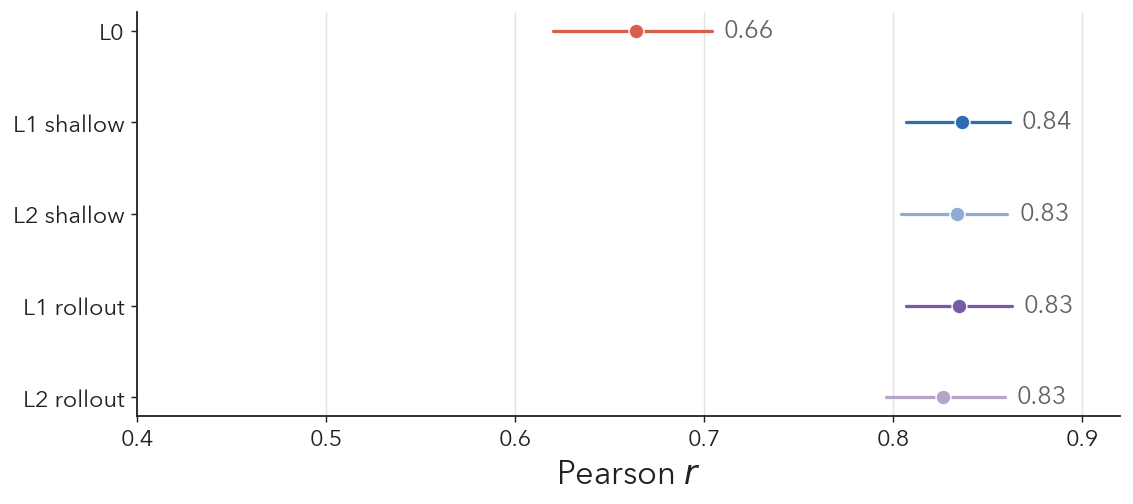

In [5]:
ci_r_univ, boot_r_univ = bootstrap_over_participants(
    dm["joe_univ"],
    datasets["joe_univ"],
    n_boot=N_BOOT_POSTER,
    seed=BOOT_SEED,
)

fig, ax, fit_r_summary = plot_bootstrap_intervals(
    boot_r_univ,
    order=MODEL_ORDER,
    xlabel="Pearson $r$",
    title=TITLES["fit_univ"],
    xlim=LIMITS["fit_r"],
    value_decimals=2,
    figsize=(8.4, 4.7),
    stem="01_fit_universalizability_r",
)

fit_r_summary.round(3)


## Statistical contrasts for poster and session

These tests use **paired bootstrap draws**: within each bootstrap iteration, the same resampled participants contribute to every model. The reported contrasts therefore test differences between models directly rather than comparing overlapping confidence intervals.

Primary contrasts:

1. **Shallow prediction − no prediction**: L1 heuristic minus L0.
2. **Rollout − shallow prediction**: real L1 minus L1 heuristic.
3. For moral judgments, the same contrasts are applied to incremental $\Delta R^2$.

The notebook reports two-sided bootstrap $p$ values by default. One-sided tail probabilities are also included for descriptive use, but the two-sided values are the safer poster/session statistics unless a directional test was preregistered.


In [6]:
def paired_bootstrap_contrast(boot, model_a, model_b, ci=95):
    """Summarize paired bootstrap difference: model_a - model_b."""
    a = np.asarray(boot[model_a], dtype=float)
    b = np.asarray(boot[model_b], dtype=float)
    mask = np.isfinite(a) & np.isfinite(b)
    diff = a[mask] - b[mask]
    if diff.size == 0:
        raise ValueError(f"No finite paired draws for {model_a} and {model_b}")

    alpha = (100 - ci) / 2
    lo, hi = np.percentile(diff, [alpha, 100 - alpha])

    # Bootstrap tail probabilities relative to zero.
    p_gt_0 = np.mean(diff > 0)
    p_lt_0 = np.mean(diff < 0)
    p_two_sided = min(1.0, 2 * min(p_gt_0, p_lt_0))

    return {
        "comparison": f"{MODEL_LABELS.get(model_a, model_a)} − {MODEL_LABELS.get(model_b, model_b)}",
        "model_a": model_a,
        "model_b": model_b,
        "mean_diff": np.mean(diff),
        "median_diff": np.median(diff),
        "ci_lo": lo,
        "ci_hi": hi,
        "p_two_sided": p_two_sided,
        "p_a_gt_b": 1 - p_gt_0,
        "prob_a_gt_b": p_gt_0,
        "n_boot": diff.size,
    }


def contrast_table(boot, contrasts, metric_label):
    rows = []
    for model_a, model_b, claim in contrasts:
        row = paired_bootstrap_contrast(boot, model_a, model_b)
        row["claim"] = claim
        row["metric"] = metric_label
        rows.append(row)
    cols = [
        "metric", "claim", "comparison", "mean_diff", "ci_lo", "ci_hi",
        "p_two_sided", "prob_a_gt_b", "n_boot"
    ]
    return pd.DataFrame(rows)[cols]


PRIMARY_CONTRASTS = [
    ("L1 heuristic", "L0", "Shallow prediction improves on no prediction"),
    ("real L1", "L1 heuristic", "Rollout improves on shallow prediction"),
]


In [7]:
# Paired contrasts in fit to explicit universalizability judgments.
r_contrasts = contrast_table(
    boot_r_univ,
    PRIMARY_CONTRASTS,
    metric_label="Δ Pearson r",
)
display(r_contrasts.round({
    "mean_diff": 3, "ci_lo": 3, "ci_hi": 3,
    "p_two_sided": 4, "prob_a_gt_b": 4,
}))

r_contrasts.to_csv(FIG_DIR / "paired_contrasts_universalizability_r.csv", index=False)


,metric,claim,comparison,mean_diff,ci_lo,ci_hi,p_two_sided,prob_a_gt_b,n_boot
0,Δ Pearson r,Shallow prediction improves on no prediction,L1 shallow − L0,0.173,0.142,0.204,0.000,1.000,1000
1,Δ Pearson r,Rollout improves on shallow prediction,L1 rollout − L1 shallow,-0.001,-0.015,0.014,0.828,0.414,1000


In [8]:
# Optional pairwise checks for the session.
# With 10-run simulation summaries, real L1 vs. one-step L1 may be indistinguishable.
for a, b in [
    ("L1 heuristic", "L0"),
    ("L2 heuristic", "L1 heuristic"),
    ("L1 heuristic", "real L1"),
]:
    result = bootstrap_pairwise(
        dm["joe_univ"], datasets["joe_univ"],
        a, b, metric="r",
        n_boot=N_BOOT_POSTER, seed=BOOT_SEED,
    )
    print(
        f"{a} − {b}: Δr={result['diff_mean']:+.3f} "
        f"[{result['ci_lo']:+.3f}, {result['ci_hi']:+.3f}], "
        f"directional p={result['p_value']:.3f}"
    )


L1 heuristic − L0: Δr=+0.173 [+0.142, +0.204], directional p=0.000
L2 heuristic − L1 heuristic: Δr=-0.003 [-0.009, +0.005], directional p=0.792
L1 heuristic − real L1: Δr=+0.001 [-0.014, +0.015], directional p=0.414


## 5. Cleaner scatterplots

All scenarios use the same neutral marker. The only color identifies the model through its regression line and panel heading. This removes the unnecessary visual claim that scenario-name categories are theoretically meaningful.

For the poster, two panels are usually enough: L0 and one-step L1. Add `real L1` to `SCATTER_TAGS` for completeness or a talk slide.


fsSelection bit 5 (bold) and head table macStyle bit 0 (bold) should match


Saved: figures/poster_clean/02_model_human_scatters.pdf / .svg / .png


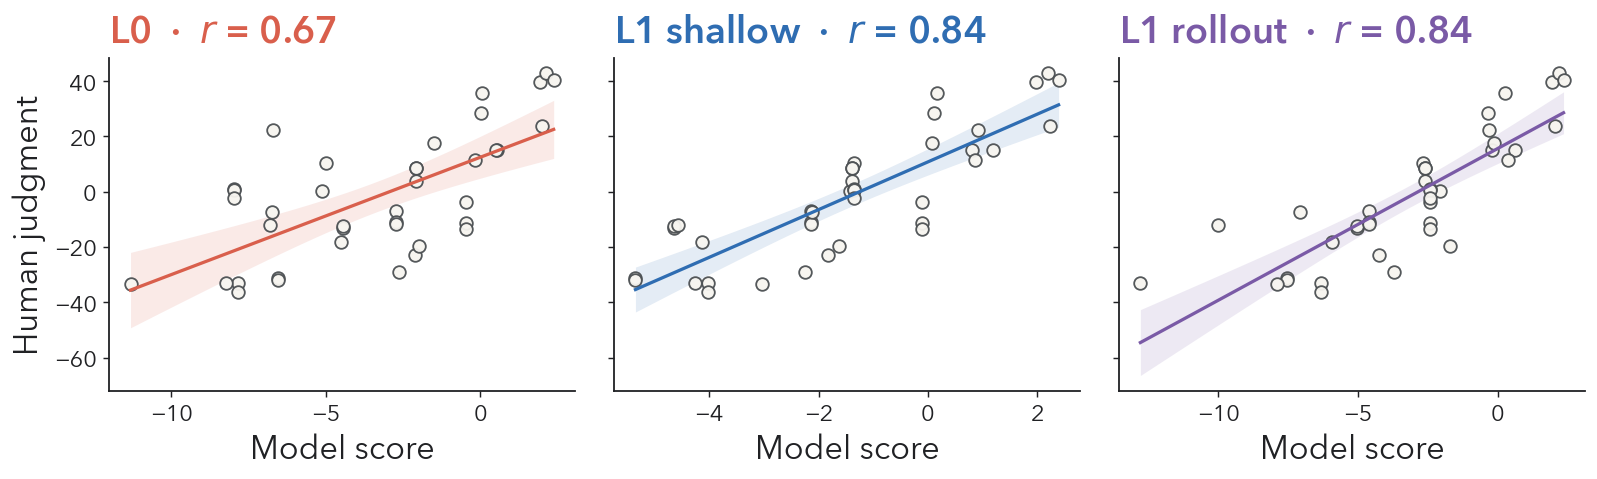

In [9]:
SCATTER_TAGS = ["L0", "L1 heuristic", "real L1"]

fig, axes = plot_model_human_scatters(
    dm["joe_univ"],
    datasets["joe_univ"],
    tags=SCATTER_TAGS,
    title=TITLES["scatter"],
    xlabel="Model score",
    ylabel="Human judgment",
    label_outliers=0,   # set to 2 or 3 to label the largest residuals
    stem="02_model_human_scatters",
)


### Optional: compare the two model outputs directly

This is not required on the poster. It is useful for diagnosing where one-step L1 and full-simulation L1 diverge. Neutral points and a diagonal make the comparison readable without map-type colors.


Saved: figures/poster_clean/optional_L1h_vs_realL1.pdf / .svg / .png


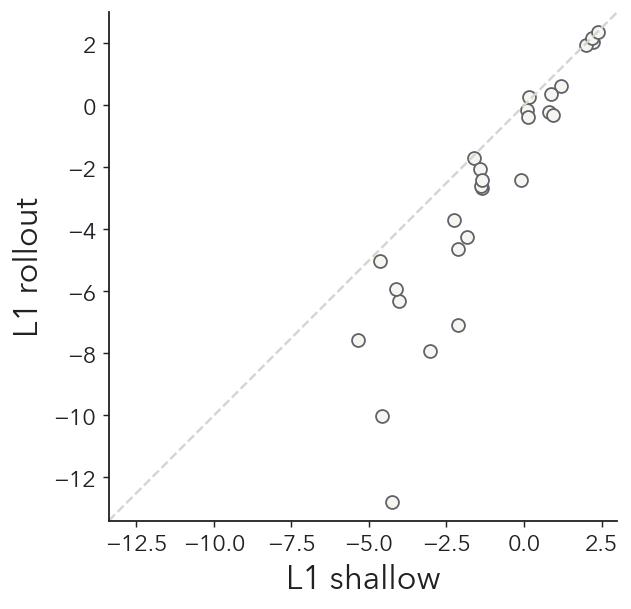

In [10]:
def plot_model_vs_model_clean(
    sims,
    tag_x="L1 heuristic",
    tag_y="real L1",
    metric="univ_aggregate_welfare",
    labels=MODEL_LABELS,
    color="#5F6368",
    label_largest=0,
    title=None,
    stem=None,
):
    xdf = sims[tag_x][["map", metric]].rename(columns={metric: "x"})
    ydf = sims[tag_y][["map", metric]].rename(columns={metric: "y"})
    df = xdf.merge(ydf, on="map").dropna()

    lo = min(df.x.min(), df.y.min())
    hi = max(df.x.max(), df.y.max())
    margin = 0.04 * (hi - lo)
    lo, hi = lo - margin, hi + margin

    fig, ax = plt.subplots(figsize=(5.3, 5.0))
    ax.plot([lo, hi], [lo, hi], color=STYLE["grid"], linewidth=1.3, linestyle="--")
    ax.scatter(
        df.x, df.y,
        s=STYLE["marker_size"] * 0.75,
        facecolor=STYLE["point_fill"],
        edgecolor=color, linewidth=1.0,
    )

    if label_largest:
        df["difference"] = np.abs(df.y - df.x)
        for _, row in df.nlargest(label_largest, "difference").iterrows():
            ax.annotate(
                row["map"], (row.x, row.y),
                xytext=(5, 5), textcoords="offset points",
                fontsize=STYLE["annotation_fontsize"] - 3,
                color=STYLE["secondary_text"],
            )

    ax.set_xlabel(labels.get(tag_x, tag_x))
    ax.set_ylabel(labels.get(tag_y, tag_y))
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal", adjustable="box")
    if title:
        ax.set_title(title, loc="left", fontweight="semibold")
    clean_axes(ax)
    fig.tight_layout()
    if stem:
        export_figure(fig, stem)
    return fig, ax, df

fig, ax, model_comparison_df = plot_model_vs_model_clean(
    sims,
    tag_x="L1 heuristic",
    tag_y="real L1",
    title=None,
    label_largest=0,
    stem="optional_L1h_vs_realL1",
)


## 6. Fit versus compute — Pearson $r$

This version is intentionally compact. It is less boring than a naked scatter because:

- vertical whiskers show uncertainty in fit from the participant bootstrap;
- horizontal whiskers show the interquartile range of observed run times;
- the x-axis is logarithmic, making the 11×–40× cost difference visible without a large table.

The compute whiskers describe run-time variation, not inferential uncertainty.


Saved: figures/poster_clean/03_fit_vs_compute_r.pdf / .svg / .png


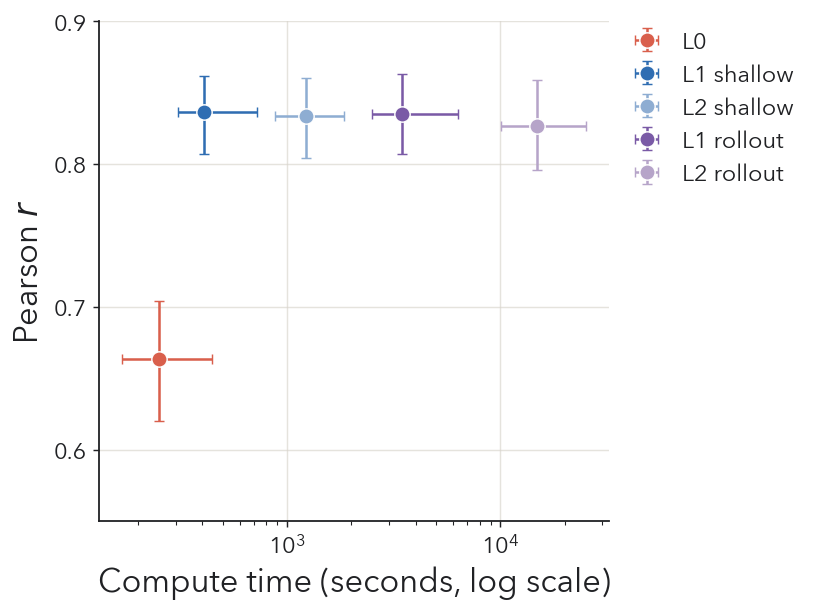

In [11]:
compute_samples = load_compute_samples(RUNS)

fig, ax = plot_fit_vs_compute(
    compute_samples,
    boot_r_univ,
    order=MODEL_ORDER,
    title=TITLES["fit_compute"],
    ylim=LIMITS["fit_compute_r"],
    show_compute_iqr=True,
    figsize=(7.0, 5.2),
    stem="03_fit_vs_compute_r",
)


## 7. Moral judgment — $\Delta R^2$ beyond outcomes

Here the incremental metric is the scientifically natural one. Welfare, harm, and inequality are genuine alternative predictors of moral judgment, so $\Delta R^2$ asks whether each model's universalization score contributes beyond them.

The first figure gives the compact US + pooled-20-country result. The second is an optional country-level forest plot in the same metric.


fsSelection bit 5 (bold) and head table macStyle bit 0 (bold) should match


Saved: figures/poster_clean/04_moral_judgment_delta_r2.pdf / .svg / .png


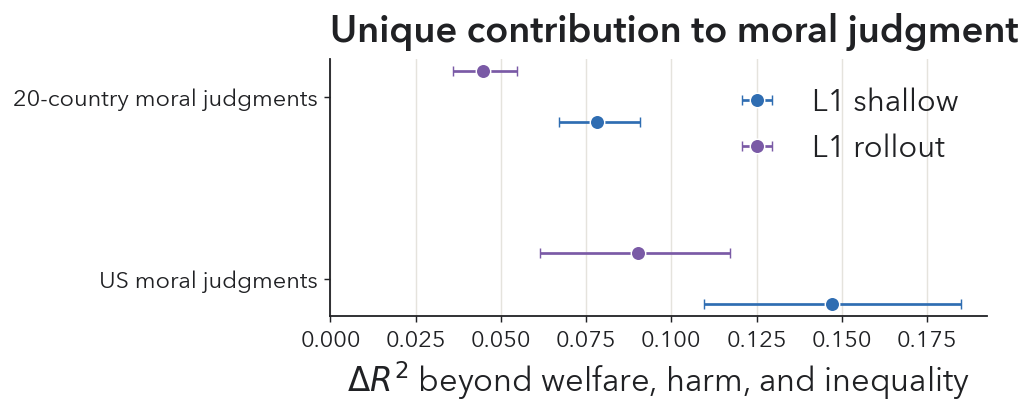

In [12]:
moral_boot = {}

_, moral_boot["joe_moral"] = bootstrap_delta_r2(
    dm["joe_moral"], datasets["joe_moral"],
    n_boot=N_BOOT_POSTER, seed=BOOT_SEED,
)
_, moral_boot["logan_moral"] = bootstrap_delta_r2(
    dm["logan_moral"], datasets["logan_moral"],
    n_boot=N_BOOT_POSTER, seed=BOOT_SEED,
)

MORAL_DATASET_LABELS = {
    "joe_moral": "US moral judgments",
    "logan_moral": "20-country moral judgments",
}

fig, ax = plot_moral_dr2(
    moral_boot,
    MORAL_DATASET_LABELS,
    model_tags=("L1 heuristic", "real L1"),
    title=TITLES["moral_dr2"],
    xlim=LIMITS["moral_dr2"],
    figsize=(8.0, 3.5),
    stem="04_moral_judgment_delta_r2",
)


In [13]:
# Pooled moral-judgment tests.
# First: does each model add predictive value beyond outcome-based controls?
# Second: paired differences of ΔR² across models, mirroring the r contrasts above.

def bootstrap_effect_vs_zero(values, label, ci=95):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    alpha = (100 - ci) / 2
    lo, hi = np.percentile(values, [alpha, 100 - alpha])
    p_gt_0 = np.mean(values > 0)
    p_lt_0 = np.mean(values < 0)
    return {
        "model": label,
        "mean_delta_r2": np.mean(values),
        "ci_lo": lo,
        "ci_hi": hi,
        "p_two_sided_vs_0": min(1.0, 2 * min(p_gt_0, p_lt_0)),
        "prob_gt_0": p_gt_0,
        "n_boot": values.size,
    }


moral_test_tables = {}

for dataset_key, dataset_label in MORAL_DATASET_LABELS.items():
    boot = moral_boot[dataset_key]

    effect_rows = [
        bootstrap_effect_vs_zero(boot[tag], MODEL_LABELS.get(tag, tag))
        for tag in ["L0", "L1 heuristic", "real L1"]
    ]
    effects = pd.DataFrame(effect_rows)
    effects.insert(0, "dataset", dataset_label)

    contrasts = contrast_table(
        boot,
        PRIMARY_CONTRASTS,
        metric_label="Difference in ΔR²",
    )
    contrasts.insert(0, "dataset", dataset_label)

    moral_test_tables[dataset_key] = {
        "effects_vs_zero": effects,
        "paired_model_contrasts": contrasts,
    }

    print(f"\n{dataset_label}: each model's ΔR² versus zero")
    display(effects.round({
        "mean_delta_r2": 4, "ci_lo": 4, "ci_hi": 4,
        "p_two_sided_vs_0": 4, "prob_gt_0": 4,
    }))

    print(f"{dataset_label}: paired differences in ΔR²")
    display(contrasts.round({
        "mean_diff": 4, "ci_lo": 4, "ci_hi": 4,
        "p_two_sided": 4, "prob_a_gt_b": 4,
    }))

    effects.to_csv(FIG_DIR / f"{dataset_key}_delta_r2_vs_zero.csv", index=False)
    contrasts.to_csv(FIG_DIR / f"{dataset_key}_paired_delta_r2_contrasts.csv", index=False)



US moral judgments: each model's ΔR² versus zero


,dataset,model,mean_delta_r2,ci_lo,ci_hi,p_two_sided_vs_0,prob_gt_0,n_boot
0,US moral judgments,L0,0.0341,0.0170,0.0524,0.0,1.0,1000
1,US moral judgments,L1 shallow,0.1472,0.1095,0.1851,0.0,1.0,1000
2,US moral judgments,L1 rollout,0.0901,0.0615,0.1171,0.0,1.0,1000


US moral judgments: paired differences in ΔR²


,dataset,metric,claim,comparison,mean_diff,ci_lo,ci_hi,p_two_sided,prob_a_gt_b,n_boot
0,US moral judgments,Difference in ΔR²,Shallow prediction improves on no prediction,L1 shallow − L0,0.1131,0.0868,0.1404,0.0,1.0,1000
1,US moral judgments,Difference in ΔR²,Rollout improves on shallow prediction,L1 rollout − L1 shallow,-0.0571,-0.0743,-0.0420,0.0,0.0,1000



20-country moral judgments: each model's ΔR² versus zero


,dataset,model,mean_delta_r2,ci_lo,ci_hi,p_two_sided_vs_0,prob_gt_0,n_boot
0,20-country moral judgments,L0,0.0258,0.0193,0.0332,0.0,1.0,1000
1,20-country moral judgments,L1 shallow,0.0783,0.0671,0.0908,0.0,1.0,1000
2,20-country moral judgments,L1 rollout,0.0449,0.0359,0.0547,0.0,1.0,1000


20-country moral judgments: paired differences in ΔR²


,dataset,metric,claim,comparison,mean_diff,ci_lo,ci_hi,p_two_sided,prob_a_gt_b,n_boot
0,20-country moral judgments,Difference in ΔR²,Shallow prediction improves on no prediction,L1 shallow − L0,0.0525,0.0440,0.0618,0.0,1.0,1000
1,20-country moral judgments,Difference in ΔR²,Rollout improves on shallow prediction,L1 rollout − L1 shallow,-0.0334,-0.0386,-0.0284,0.0,0.0,1000


### What to report on the poster

The most economical reporting is:

- **Universalizability fit:** L1 shallow minus L0, followed by its 95% paired-bootstrap CI.
- **Rollout comparison:** real L1 minus L1 shallow, preferably as an effect estimate and CI rather than merely “not significant.”
- **Moral judgments:** pooled L1-shallow $\Delta R^2$ versus zero, plus the two paired $\Delta R^2$ contrasts if space permits.

Do not infer model differences from overlapping individual confidence intervals; use the paired contrast table generated above.


### Optional country-level $\Delta R^2$ forest plot

This can take a few minutes without `fast_bootstrap`. For the poster, the pooled result may be clearer; keep the country plot only if its pattern is visually stable and legible at print size.


In [14]:
RUN_COUNTRY_BOOTSTRAPS = False

if RUN_COUNTRY_BOOTSTRAPS:
    country_rows = []
    focal_tags = ["L1 heuristic", "real L1"]

    for country, experiment in sorted(logan_by_country.items()):
        country_dm = build_all_design_matrices(
            {tag: sims[tag] for tag in focal_tags},
            out_df,
            experiment,
        )
        summary, boot = bootstrap_delta_r2(
            country_dm,
            experiment,
            n_boot=N_BOOT_POSTER,
            seed=BOOT_SEED,
        )
        summary = summary.set_index("tag")
        for tag in focal_tags:
            values = np.asarray(boot[tag], dtype=float)
            values = values[np.isfinite(values)]
            country_rows.append({
                "country": country,
                "tag": tag,
                "mean": np.mean(values),
                "lo": np.percentile(values, 2.5),
                "hi": np.percentile(values, 97.5),
            })

    country_dr2 = pd.DataFrame(country_rows)
    country_dr2.to_csv(FIG_DIR / "country_delta_r2.csv", index=False)

    fig, ax = plot_country_dr2(
        country_dr2,
        tag="L1 heuristic",
        pooled_boot=moral_boot["logan_moral"],
        pooled_label="Pooled (20 countries)",
        pooled_first=True,
        title=TITLES["country_dr2"],
        xlim=LIMITS["country_dr2"],
        stem="05_country_delta_r2",
    )
else:
    print("Country bootstraps skipped. Set RUN_COUNTRY_BOOTSTRAPS=True to run them.")


Country bootstraps skipped. Set RUN_COUNTRY_BOOTSTRAPS=True to run them.


## 8. Poster export checklist

- Open the exported **PDF or SVG** in PowerPoint rather than the PNG when possible.
- Keep the aspect ratio fixed when resizing.
- Confirm that PowerPoint uses **Avenir Next** rather than substituting a font.
- At final poster scale, axis labels should generally be at least 18–22 pt in the source figure.
- Use identical model colors in every chart:
  - coral = depth 0
  - blue = depth 1
  - purple = depth 2
  - lighter shade = higher model-of-others level
- Do not describe small nominal differences within the shallow family as meaningful unless the paired bootstrap supports them.
